# Extra ideas: CLEAN and filtering

These five calculations use the supplied Kepler, SoHO/GOLF and SONG observations. CLEAN follows the lecture convention of iterative time-domain sinusoidal subtraction. All calculations retain the original observation times.

Set `RUN_ANALYSIS = True` to recalculate all five experiments in order after downloading the data. Otherwise the cells display the saved results. Extra 4 uses the band selections produced by Extra 3.

In [1]:
from pathlib import Path
import importlib
import json
from IPython.display import display, Image

ROOT = Path.cwd()
RUN_ANALYSIS = False

def analyse(module, summary_file):
    if RUN_ANALYSIS:
        return importlib.import_module(module).run_analysis(ROOT, show=False)
    return json.loads((ROOT / "results" / summary_file).read_text())

print("Recalculating experiments." if RUN_ANALYSIS else "Displaying saved extra-idea results.")

Displaying saved extra-idea results.


## Extra idea 1 — CLEAN star03

The Kepler delta Scuti light curve contains 46,166 measurements over 31.530 days. CLEAN is implemented as iterative time-domain sine fitting: find the strongest residual peak, refine its frequency, then jointly refit the selected sine/cosine coefficients and a constant. The model is

$$
y_i=c+\sum_{k=1}^{K}\left[a_k\sin(2\pi f_k t_i)+b_k\cos(2\pi f_k t_i)\right]+r_i,
\qquad A_k=\sqrt{a_k^2+b_k^2},\qquad P_k=A_k^2.
$$

Times are in seconds and frequencies in Hz. All observed timestamps are retained with equal weights. The search covers 50–600 μHz, initially sampled every 0.09177 μHz. Iteration stops below four times the original mean amplitude at 2000–4000 μHz (6.178 ppm), or after 20 components.

| Strongest fitted frequency (μHz) | Amplitude (ppm) |
|---:|---:|
| 166.2423 | 4648.98 |
| 180.3379 | 4485.60 |
| 172.3868 | 3474.02 |

The run reaches the 20-component cap. RMS decreases from 5958.51 to 717.28 ppm, removing 98.55% of the original time-domain variance. The residual peak is still 215.98 ppm, above the stopping threshold: the dominant oscillations are removed, but the residual is not noise-only. Aliases, weaker oscillations and changing amplitudes can remain; extracted sinusoids are not automatically distinct physical modes.

In [2]:
star03 = analyse('extra_star03', 'extra1_star03_summary.json')
print(f"CLEAN components: {star03['components_removed']}; residual RMS: {star03['residual_rms_ppm']:.3f} ppm")

CLEAN components: 20; residual RMS: 717.276 ppm


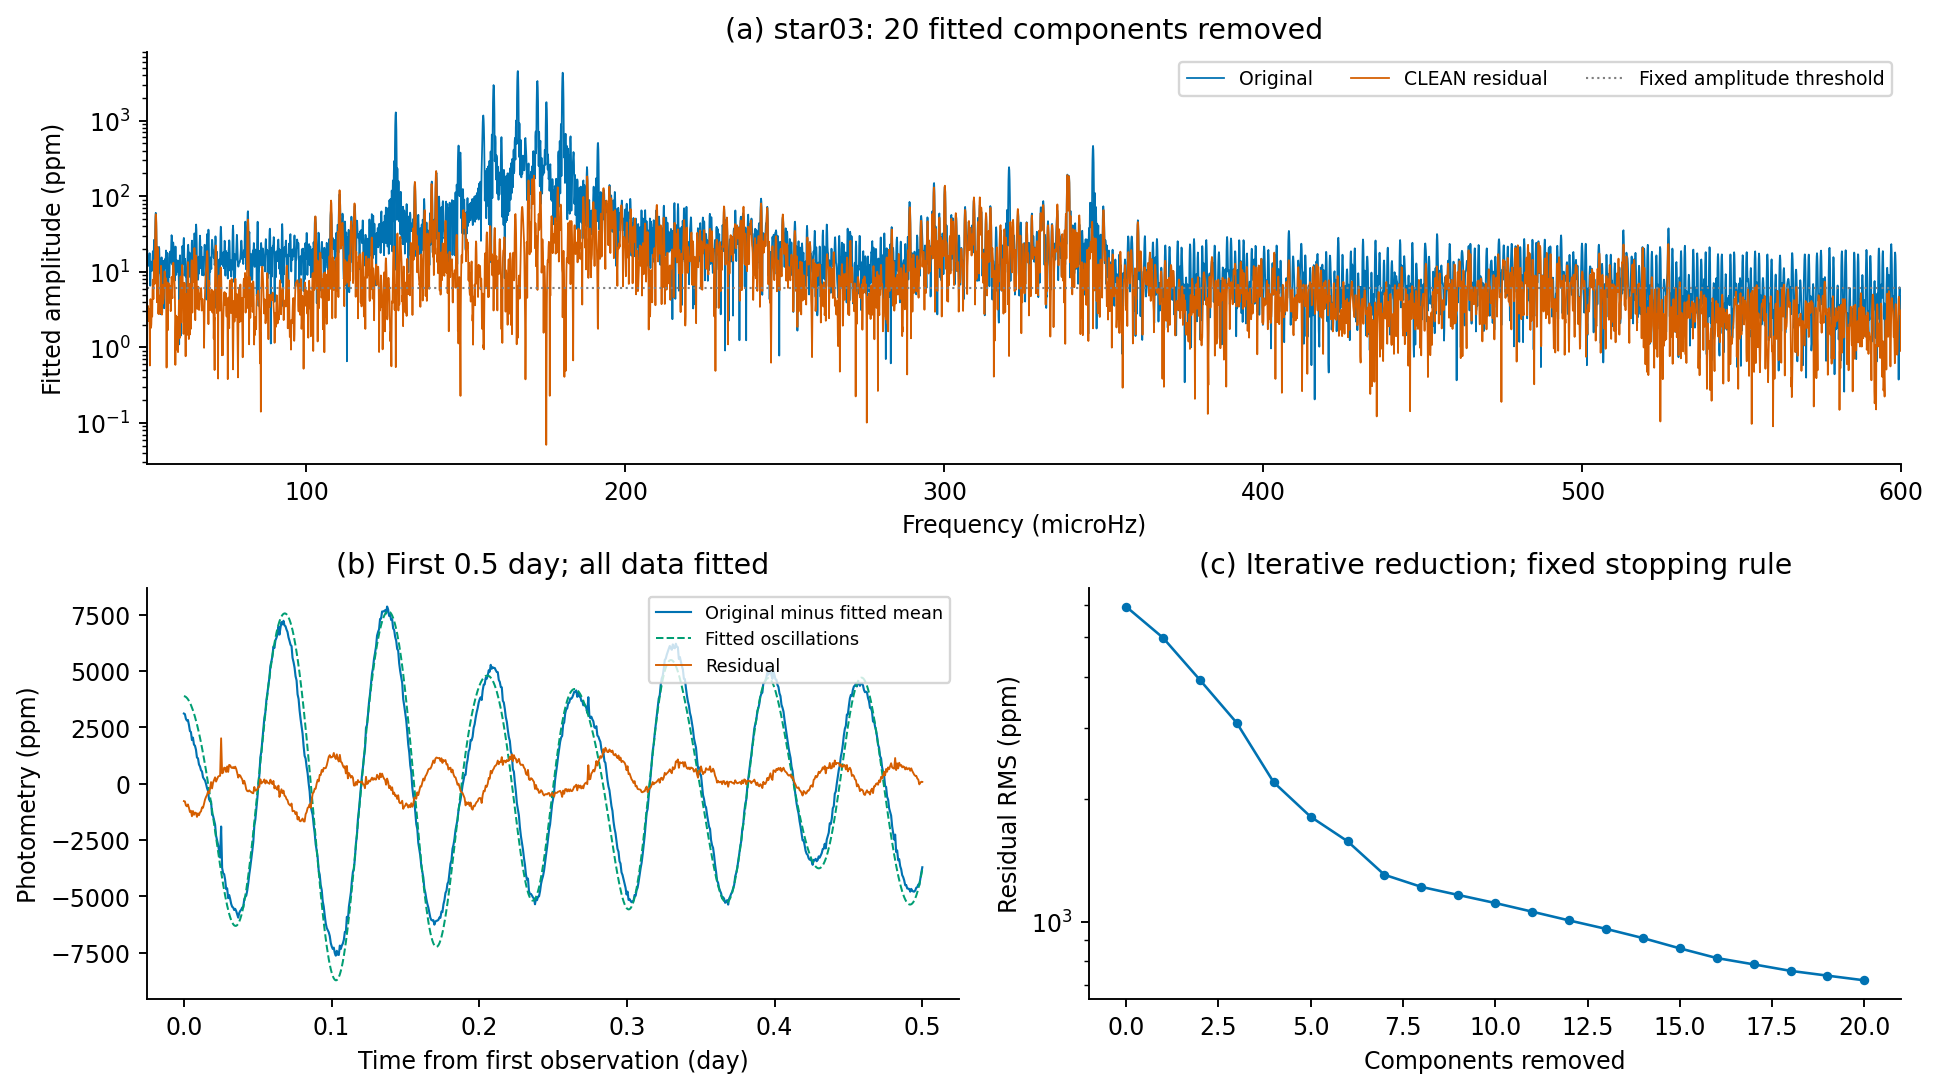

In [3]:
display(Image(filename=str(ROOT / 'figures/07_star03_clean.png')))

Figure E1. Original and CLEAN-residual spectra, a common time interval, and residual RMS during subtraction.

## Extra idea 2 — Solar high-pass filters

The SoHO/GOLF series contains 32,400 velocity observations over about 30 days. High-pass filtering subtracts a normalized Gaussian smooth evaluated at the actual timestamps, with trapezoidal time weights. Its continuous-record amplitude response is

$$
H(f)=1-\exp(-2\pi^2\sigma_t^2f^2),\qquad
\sigma_t=\frac{\sqrt{-2\ln(1-1/\sqrt{2})}}{2\pi f_c},
\qquad |H(f_c)|^2=\frac12.
$$

The requested cutoffs, 0.02, 0.1 and 1 mHz, are therefore half-power frequencies. Kernels end at five Gaussian widths. All filtered and unfiltered spectra use the same 30,840 interior observations, preventing differing edge masks from changing the comparison window. Power means fitted amplitude squared in (m/s)².

The table shows summed sampled power relative to the unfiltered spectrum in each band.

| Cutoff (mHz) | 0.002–0.02 mHz | 0.02–0.1 mHz | 2–4.5 mHz |
|---|---:|---:|---:|
| Unfiltered | 100% | 100% | 100% |
| 0.02 | 4.0698% | 90.5908% | 99.3881% |
| 0.1 | 0.02309% | 10.0433% | 99.3686% |
| 1 | 0.007857% | 0.05406% | 99.3946% |

Increasing the cutoff suppresses progressively more low-frequency variability. All three filters retain approximately 99.4% of the sampled power in the solar oscillation band. The 1 mHz filter removes the broadest low-frequency background, but also attenuates genuine signals below that cutoff. These spectral sums are comparison statistics, not PSD-integrated time-domain variances.

In [4]:
highpass = analyse('extra_highpass', 'highpass_summary.json')
print(f"Common retained samples: {highpass['retained_samples']}")

Common retained samples: 30840


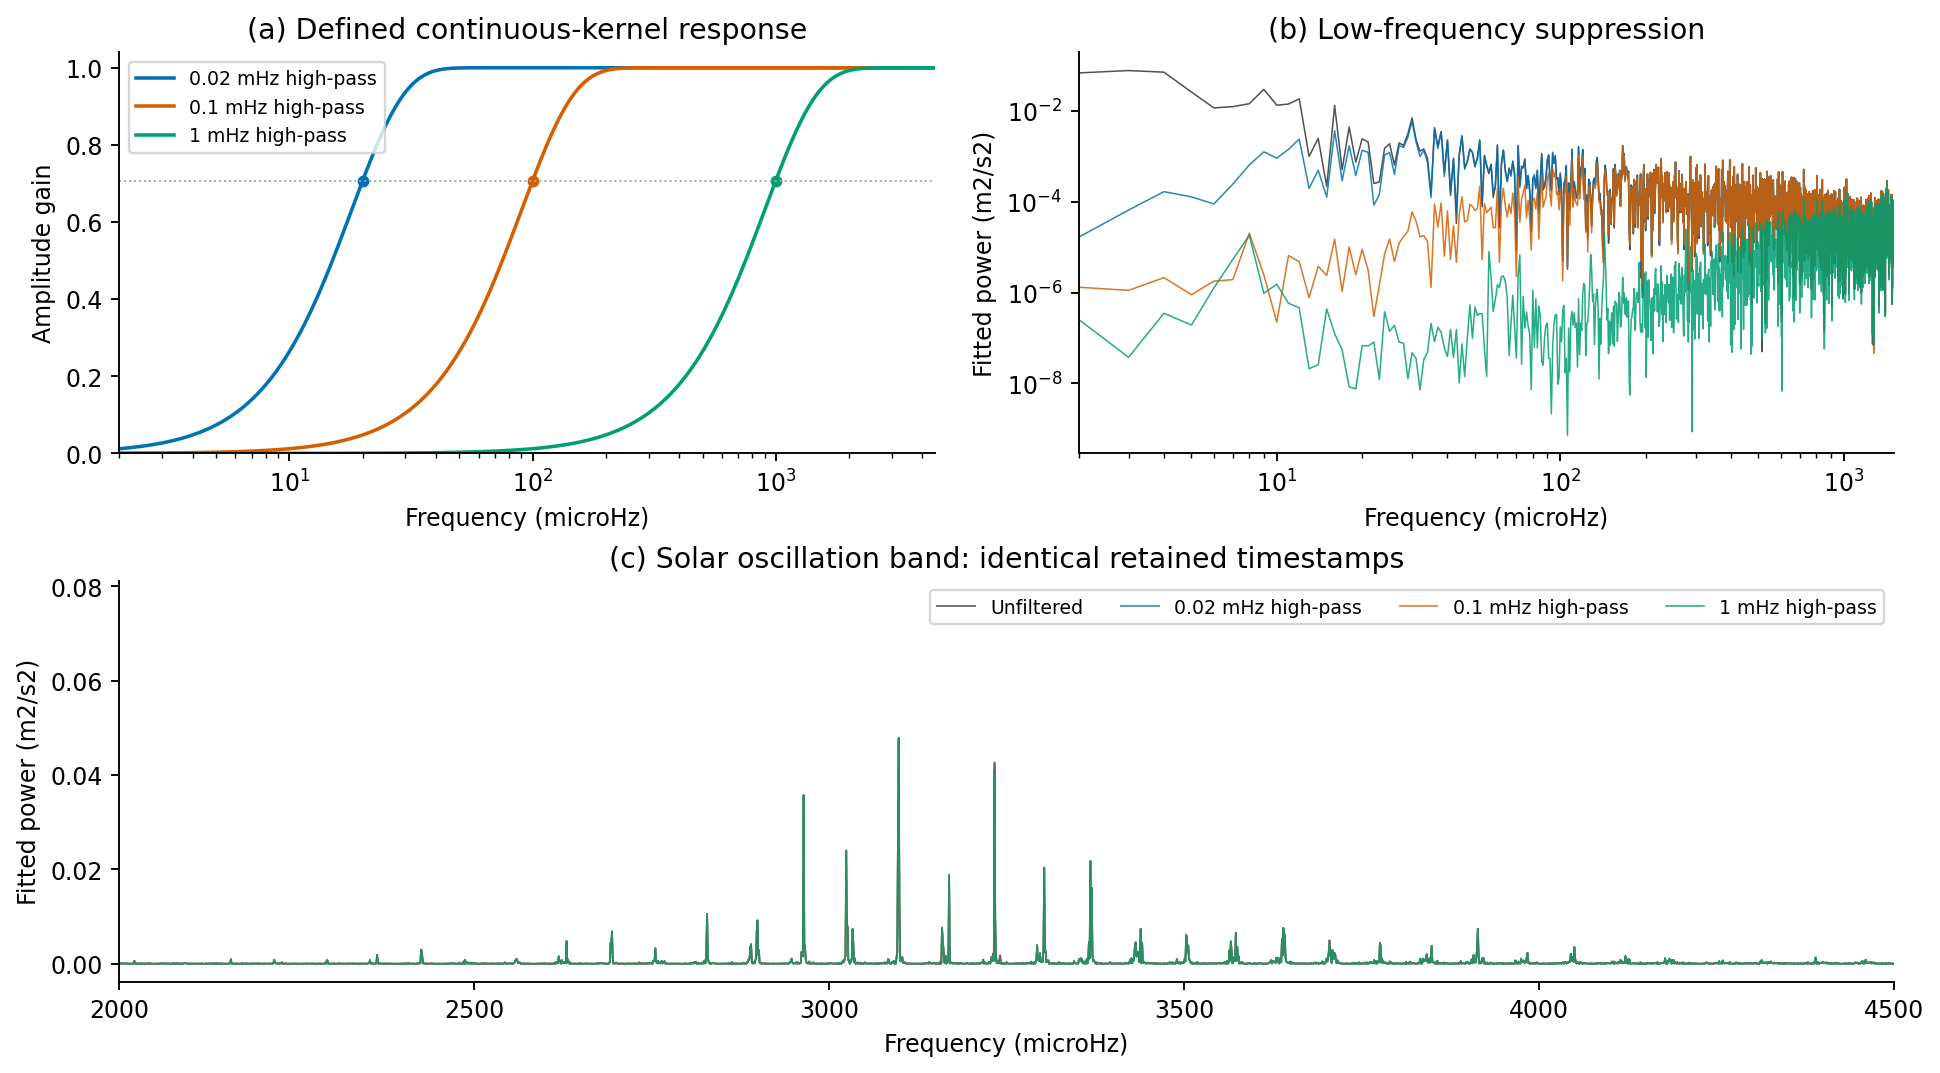

In [5]:
display(Image(filename=str(ROOT / 'figures/06_solar_highpass.png')))

Figure E2. Filter responses and the unfiltered/filtered solar power spectra at identical retained timestamps.

## Extra idea 3 — Three solar band-pass time series

The strongest interior local maximum within ±50 μHz of 2, 3 and 4 mHz is selected on a 0.2 μHz grid and refined on a 0.01 μHz grid. Each band extends ±5 μHz around the selected peak.

A constant and all sine/cosine pairs at natural frequencies inside each band are fitted jointly. The retained oscillation is

$$
v_j(t)=\sum_{f_k\in\mathcal B_j}\left[a_k\sin(2\pi f_k t)+b_k\cos(2\pi f_k t)\right],
\qquad f_k=\frac{k}{T},\qquad T=N\overline{\Delta t}.
$$

This finite-band projection uses 26 frequency pairs per band, spaced by 0.3858 μHz, and the original timestamps. The constant is excluded from the oscillation. It is a joint reconstruction rather than the lecture's independent-coefficient/window-area normalization. All observations are fitted; comparisons omit the first and last day, leaving the same 30,240 samples in every band.

| Centre (mHz) | Band (mHz) | Period (min) | Interior RMS (m/s) |
|---:|---:|---:|---:|
| 2.0203 | 2.0153–2.0253 | 8.250 | 0.03937 |
| 2.9638 | 2.9588–2.9688 | 5.623 | 0.24279 |
| 3.9841 | 3.9791–3.9891 | 4.183 | 0.09457 |

The 4 mHz signal oscillates fastest; the selected 3 mHz band has the largest RMS, 6.17 times the 2 mHz band and 2.57 times the 4 mHz band. Daily RMS changes substantially, so one short interval does not represent the full-record strength. The narrow bands can include neighboring components: beating, noise and finite coherence can all affect their envelopes, and no mode lifetime is inferred.

In [6]:
modes = analyse('extra_solar_modes', 'solar_modes_summary.json')
print('Selected centres (microHz):', [row['selected_peak_microHz'] for row in modes['bands']])

Selected centres (microHz): [2020.3000000000002, 2963.8, 3984.1]


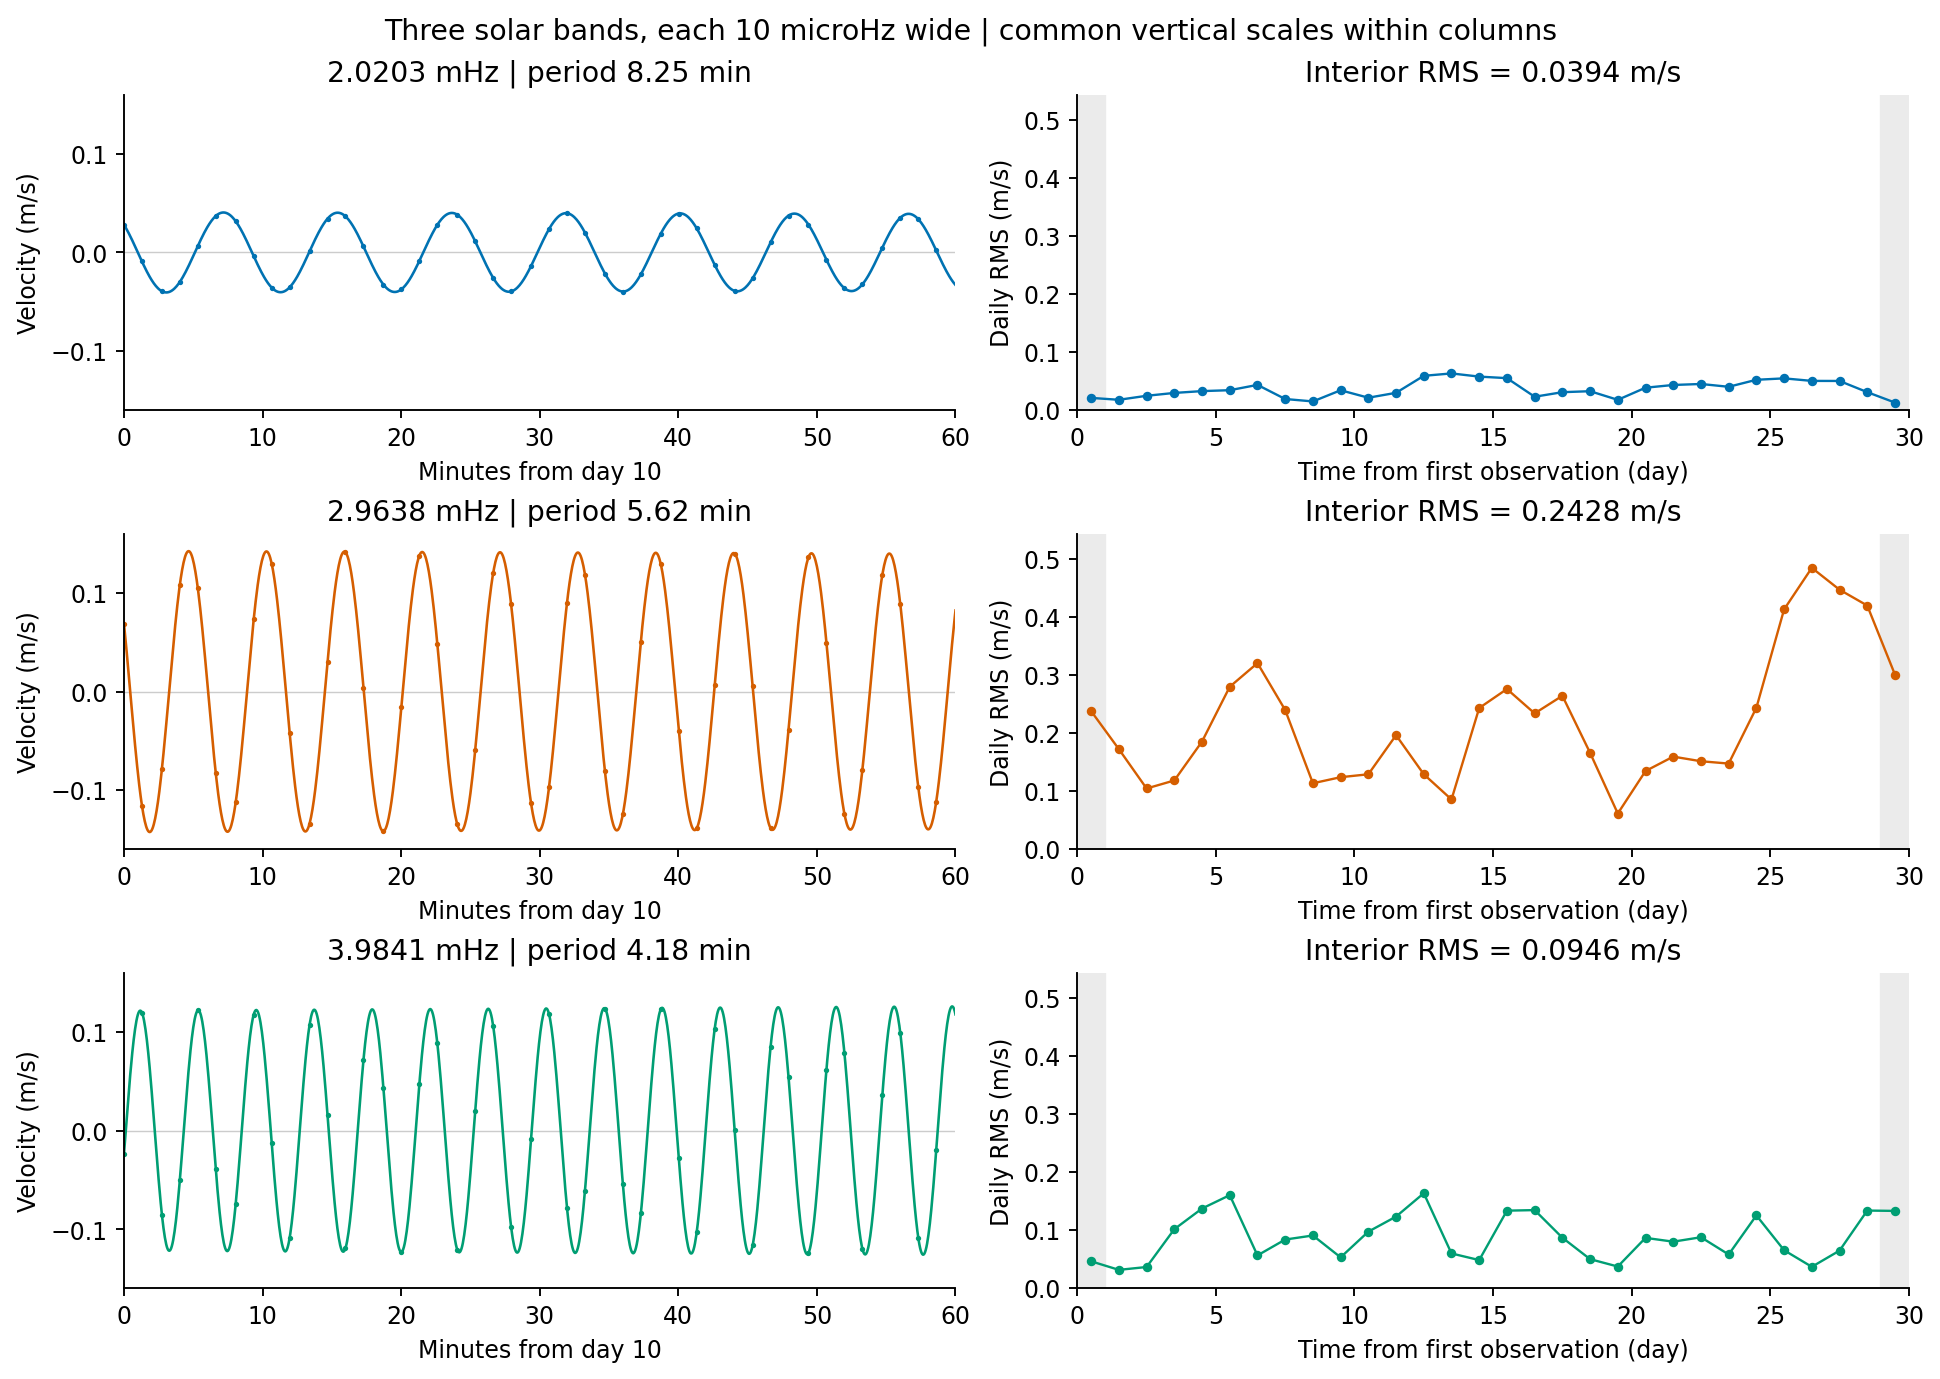

In [7]:
display(Image(filename=str(ROOT / 'figures/08_solar_modes_comparison.png')))

Figure E3. One common hour and daily RMS for the three band-pass signals, with matching vertical scales within each column.

## Extra idea 4 — CLEAN band-pass filtering

The exact three ±5 μHz bands from Extra idea 3 are reused. Within each band, CLEAN independently selects and refines residual peaks, jointly refits their coefficients and a constant, and subtracts the full fitted model. Its retained harmonic sum is the band-pass output; the subtraction residual is not the filtered oscillation.

The initial frequency step is 0.05 μHz and the subtraction gain is one. Iteration stops when the next amplitude is below 10% of the original band maximum, or after 12 components. Comparisons use the same 30,240 interior observations as Extra idea 3.

| Centre (mHz) | Components | Linear RMS (m/s) | CLEAN RMS (m/s) | Correlation |
|---:|---:|---:|---:|---:|
| 2.0203 | 12 | 0.03937 | 0.03849 | 0.97793 |
| 2.9638 | 11 | 0.24279 | 0.24170 | 0.98834 |
| 3.9841 | 12 | 0.09457 | 0.09268 | 0.96693 |

Both methods give similar oscillation strengths and daily RMS patterns, with correlations above 0.96. The selected 3 mHz band remains strongest. The linear method fits all 26 natural-grid pairs; CLEAN uses 11–12 locally refined components chosen from the data, producing visible phase and amplitude differences.

Only the 3 mHz band reaches its amplitude threshold. The other two reach the cap, so neither their completeness nor a noise-only residual is established. Component counts depend on the stopping rule and are not counts of physical stellar modes.

In [8]:
clean_modes = analyse('extra_clean_modes', 'solar_clean_modes_summary.json')
print('CLEAN/linear correlations:', [round(row['interior_correlation'], 5) for row in clean_modes['bands']])

CLEAN/linear correlations: [0.97793, 0.98834, 0.96693]


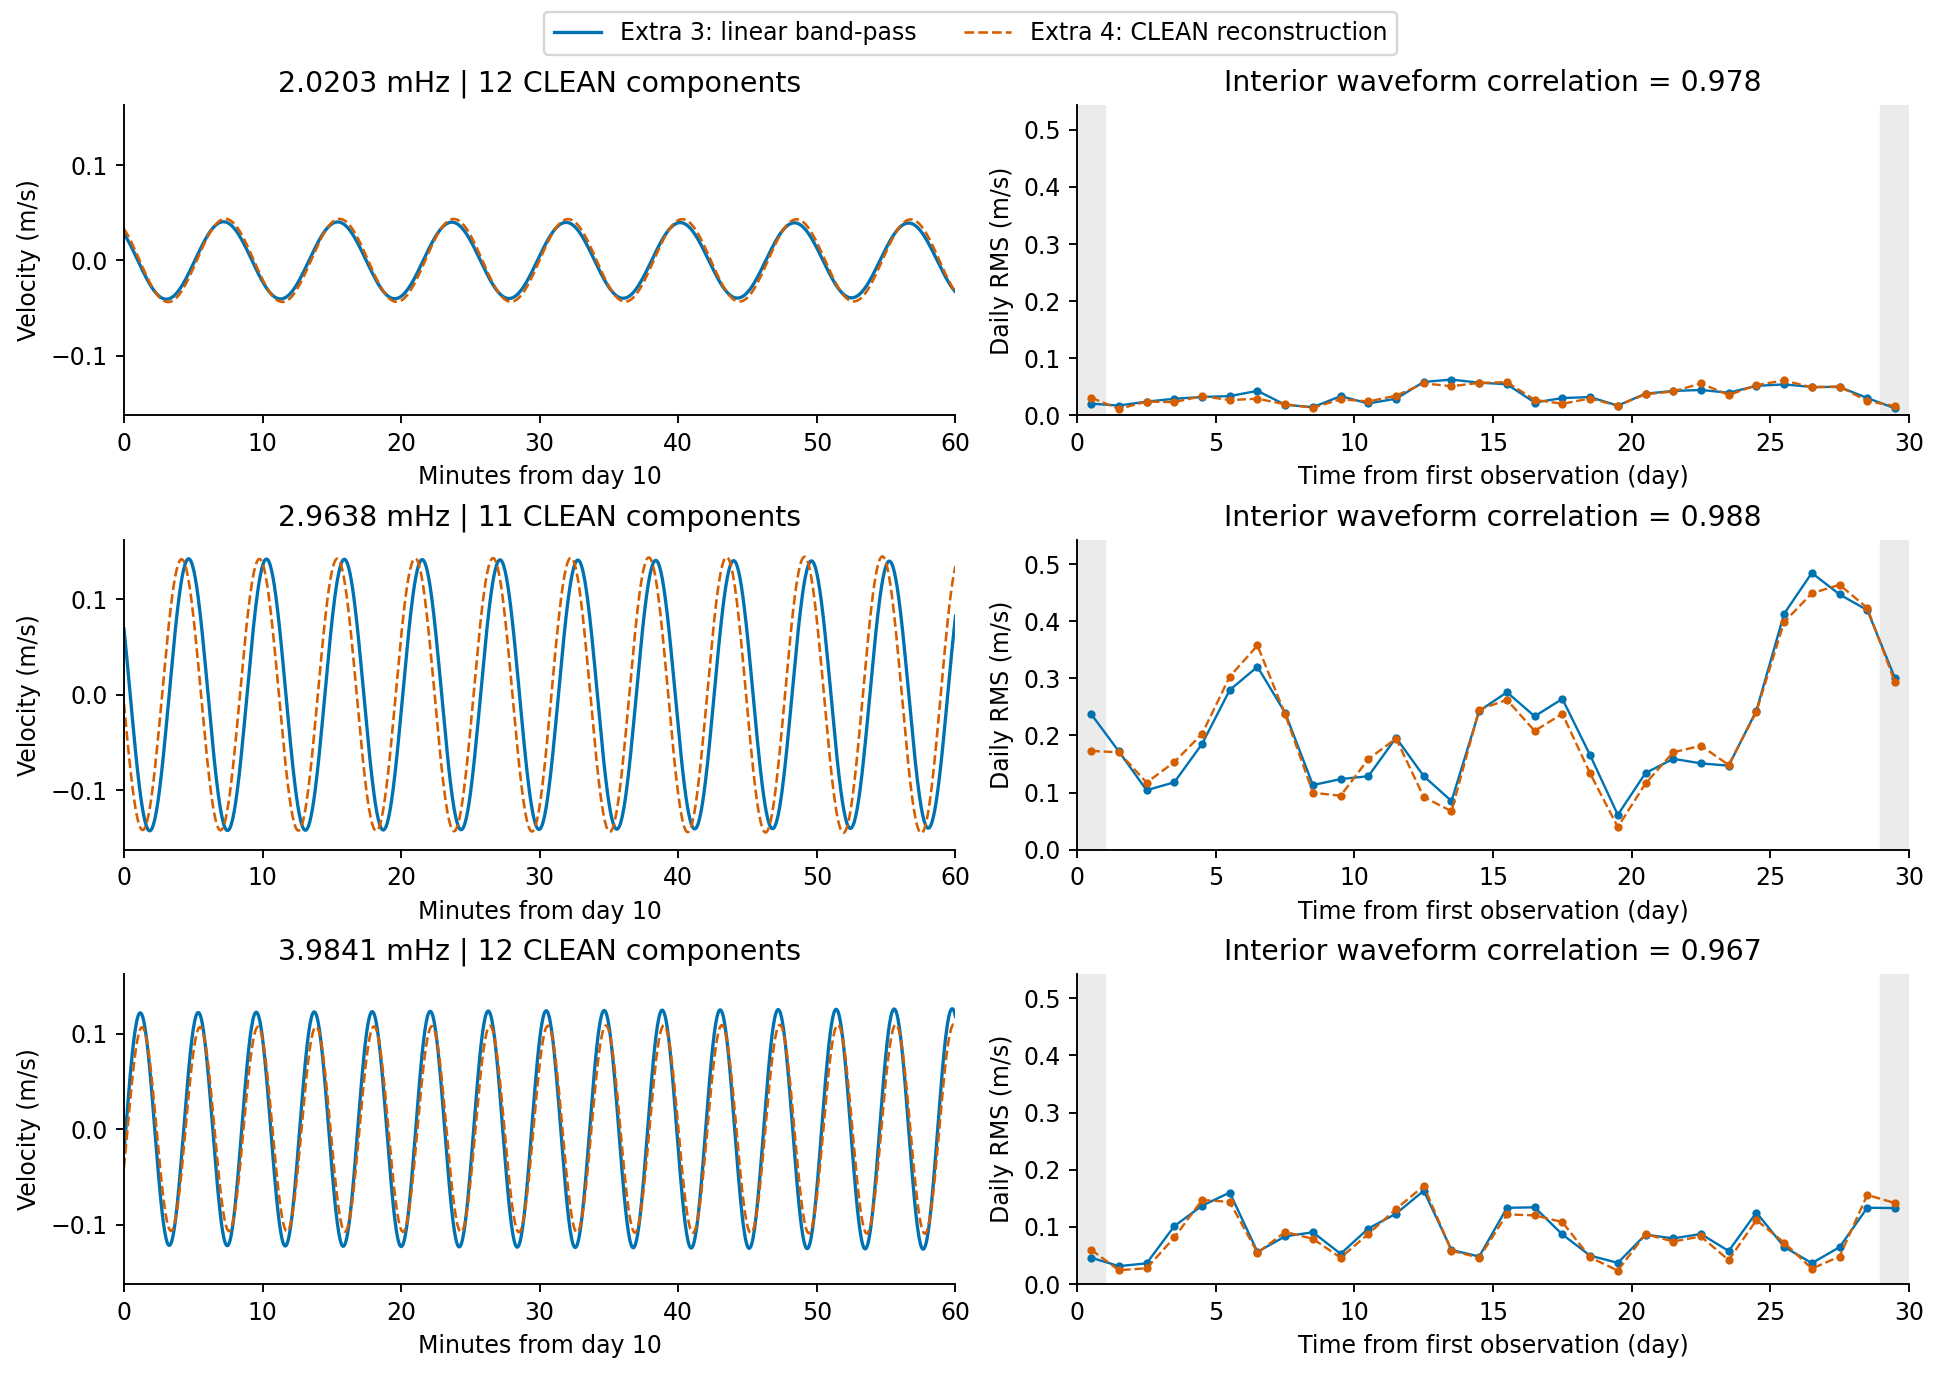

In [9]:
display(Image(filename=str(ROOT / 'figures/09_solar_clean_modes_comparison.png')))

Figure E4. Linear and CLEAN reconstructions over the same hour and their daily RMS histories.

## Extra idea 5 — Weighted CLEAN and scatter verification for 46 LMi

The SONG series contains 3,208 measurements over 54.095 days. The supplied scatter values define the requested weights:

$$
w_i=\frac1{\sigma_i^2}.
$$

Weighted CLEAN searches 5–120 μHz, with joint coefficient/intercept refitting. The stopping amplitude is four times the original mean amplitude at 1000–1800 μHz (0.26294 m/s), subject to a 20-component cap. The cap is reached, and weighted RMS decreases from 6.7525 to 3.1909 m/s. The three largest fitted amplitudes occur at 59.0074, 53.7627 and 51.2038 μHz. Residual variability and aliases can remain.

A Gaussian high-pass filter with a 0.3 mHz half-power cutoff is then applied to the CLEAN residual. Gaps longer than 30 minutes separate 49 independently filtered segments. Omitting five kernel widths at each segment end leaves 1,668 observations for the noise comparison.

The file does not state the absolute calibration of scatter. Its interpretation as independent standard deviations in m/s is therefore tested. Because fitting and filtering also change measurement noise, its covariance is propagated through both operations:

$$
C_{\mathrm{HP}}=H(I-P)\operatorname{diag}(\sigma_i^2)(I-P)^{\mathsf T}H^{\mathsf T},
\qquad s_{i,\mathrm{HP}}=\sqrt{(C_{\mathrm{HP}})_{ii}}.
$$

Here P is the weighted projection onto the fitted components and constant, conditional on the selected frequencies, and H is the segmented high-pass operator. Agreement predicts a standardized RMS near one:

$$
R=\sqrt{\frac1N\sum_i\left(\frac{r_{i,\mathrm{HP}}}{s_{i,\mathrm{HP}}}\right)^2}.
$$

| Noise comparison | Result |
|---|---:|
| Observed high-pass RMS | 1.64173 m/s |
| Predicted high-pass RMS if scatter is in m/s | 0.074134 m/s |
| Standardized RMS | 22.4858 |
| Conditional Gaussian-noise simulation 95% interval | 0.9660–1.0421 |

The scatter values **do not agree with the high-pass fluctuations under this absolute-error interpretation**. The robust standardized MAD scale is also large, 20.34, so a few outliers do not explain the mismatch. Multiplying all scatter values by 22.49 would calibrate the RMS by construction, not independently verify them. The 256 simulations condition on the selected CLEAN frequencies. Unspecified calibration, correlated noise and remaining stellar variability may contribute; the residual cannot be assumed to be purely instrumental noise.

In [10]:
lmi = analyse('extra_lmi', 'extra5_summary.json')
print(f"Standardized residual RMS: {lmi['normalized_rms_if_scatter_m_per_s']:.5f}")
print('Absolute scatter-scale agreement:', lmi['absolute_scatter_scale_supported'])

Standardized residual RMS: 22.48583
Absolute scatter-scale agreement: False


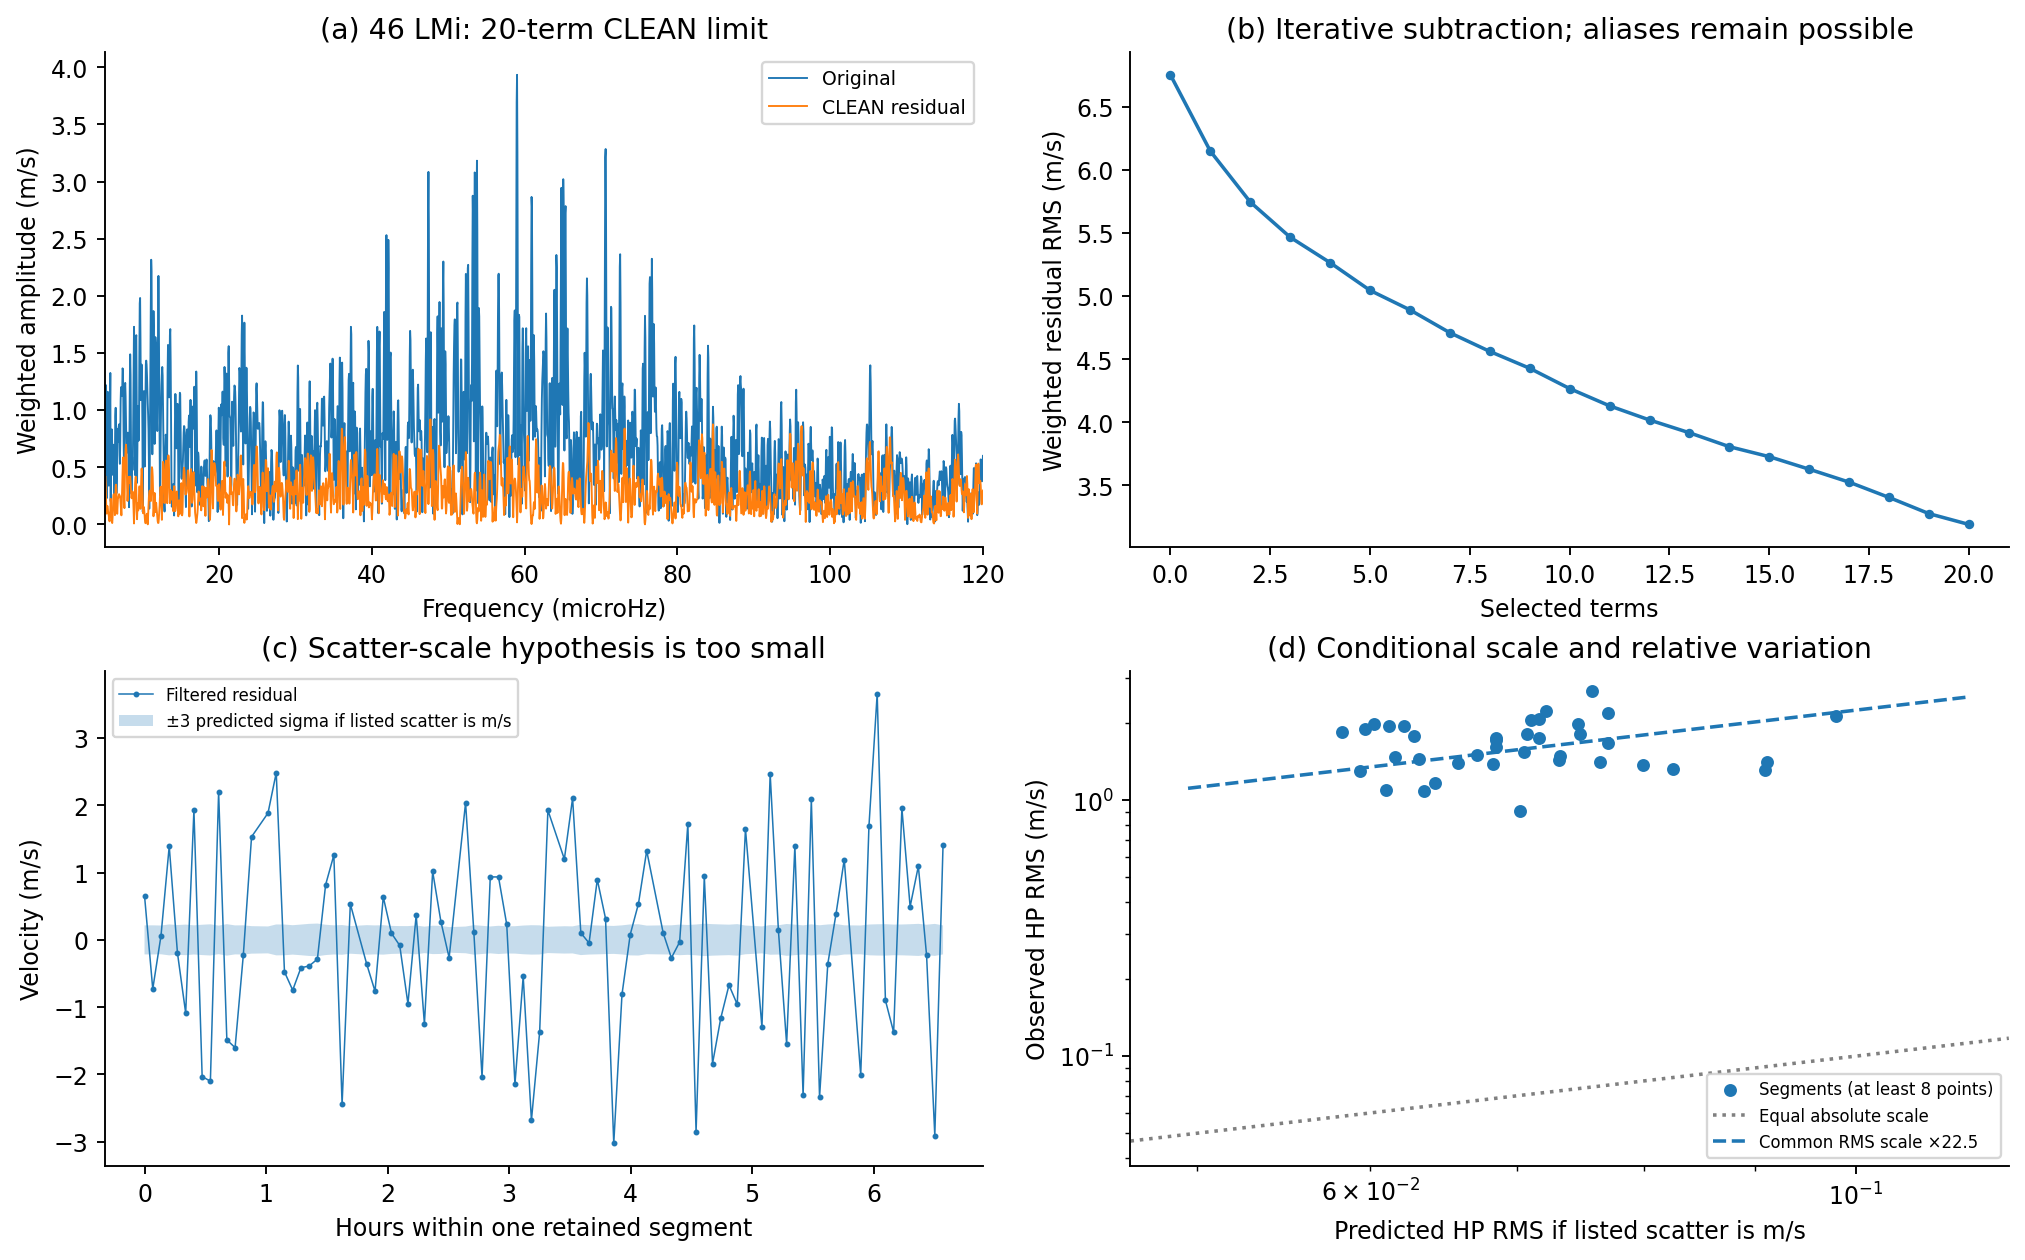

In [11]:
display(Image(filename=str(ROOT / 'figures/10_46lmi_clean_noise.png')))

Figure E5. Weighted CLEAN spectra and convergence, filtered residuals versus predicted scatter, and segment noise comparisons.

## Sources

D. Stello, *PHYS4143 Time Series Lectures* (2026): Lecture 1, page 65 (the five tasks), and Lectures 5–6 (CLEAN and filtering). Data: [course observation directory](https://www.physics.usyd.edu.au/~stello/timeseries/).